## Multi-dimensional OU process

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from jax import random
import time
import sys
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")
import ranndy_jax
import plotter
from plotter import *
import importlib
importlib.reload(ranndy_jax)
importlib.reload(plotter)
from ranndy_jax import RaNNDy, VAMPNets
import d3s.domain as domain
import d3s.algorithms as algorithms
import d3s.observables as observables
#import deeptime as dt
plt.ion()

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'         
plt.rcParams['font.serif'] = ['Computer Modern Serif']  

In [2]:
dim = 2

if dim == 1:
    data = sp.io.loadmat('../data/ou_data.mat')  #TODO: 1 dimensional OU data
    x = data['ou_data']
    X = x[:, :-1]
    Y = x[:, 1:]

else:
    # TODO: For multi-dim OU processes
    A = np.zeros((dim, dim))

    for i in range(dim):
        A[i, i] = 2

    for i in range(dim - 1):
        A[i, i + 1] = -(i + 1) / dim
        A[i + 1, i] = -(i + 1) / dim

    print("A", A)
    A = -A

    # A = np.array([[-1.5, 1], [0, -2.0]])
    da, Va = np.linalg.eig(A)
    print('Eigvals of A: ', da)

    np.random.seed(0)

    dt = 0.1
    n_steps = 50000

    sigma = 0.25

    traj = np.zeros((n_steps, dim))


    for t in range(n_steps - 1):
        dW = np.sqrt(dt) * np.random.randn(dim)
        traj[t+1] = traj[t] + A @ traj[t] * dt + np.sqrt(sigma) * dW

    X = traj[:-1:1].T
    Y = traj[1::1].T



    psi = observables.monomials(3)

    K, dk, Vk = algorithms.edmd(X, Y, psi, operator='K')

    eigf = Vk.T @ psi(X)

    print('Koopman generator d:', np.log(dk) / dt)

    eigmat = np.zeros((5, 5))    # TODO: Change the size of the matrix according to the dimension
    for i in range(5):
        for j in range(5):
                    #  for k in range(5):
                    #     for n in range(5):
                    eigmat[i, j] = i*da[0] + j*da[1] #+ k*da[2] + n*da[3]

    print(eigmat)

A [[ 2.  -0.5]
 [-0.5  2. ]]
Eigvals of A:  [-1.5 -2.5]
Koopman generator d: [ 8.88178420e-15+0.j -1.61951650e+00+0.j -2.89009524e+00+0.j
 -3.25891801e+00+0.j -4.42003610e+00+0.j]
[[ -0.   -2.5  -5.   -7.5 -10. ]
 [ -1.5  -4.   -6.5  -9.  -11.5]
 [ -3.   -5.5  -8.  -10.5 -13. ]
 [ -4.5  -7.   -9.5 -12.  -14.5]
 [ -6.   -8.5 -11.  -13.5 -16. ]]


In [3]:
# DOminant eigenvalues of the generator

exact_eigv_gen = np.sort(np.ravel(eigmat))[-5:]
vamp_gen = np.sum(exact_eigv_gen)
print(exact_eigv_gen)
print(vamp_gen)

[-4.  -3.  -2.5 -1.5 -0. ]
-11.0


In [5]:
# Experiment to plot loss surface of RaNNDy

#%matplotlib inline


random_state = 0  # Random state for reproducibility
n_eigfuncs = 5  
key = random.PRNGKey(seed=0)
w_init = [None, 1.0, 1.0]
dist_w_list = ['normal', 'lecun_normal', 'he_uniform', 'uniform', 'glorot_uniform']
dist_b_list = ['normal', 'uniform', 'zeros', 'ones']
# omega_b_list = [0.001, 0.02, 0.03, 0.08, 0.1, 0.2, 0.3]
# omega_w_list = [0.001, 0.02, 0.03, 0.06, 0.1, 0.2, 0.3, 0.5, 1.0]
vampscores_exp_ls = np.zeros((len(dist_w_list), len(dist_b_list)))

for i in range(len(dist_w_list)):
    for j in range(len(dist_b_list)):
        ranndy_exp = RaNNDy(
        X=X,
        operator='koopman',
        hidden_sizes=[256, 512, 256],
        activation="tanh",
        init_weights_dist=dist_w_list[i], 
        init_weights_std=1.0,
        init_bias_dist=dist_b_list[j],
        init_bias_std=1.0,
        random_state=random_state,
    )
        _, eigval_exp, _ = ranndy_exp.operator_eig_decomp(X=X, Y=Y, Z=None, n=n_eigfuncs, epsilon=1e-5)
        vampscores_exp_ls[i, j] = np.sum(np.real(eigval_exp)[:3])




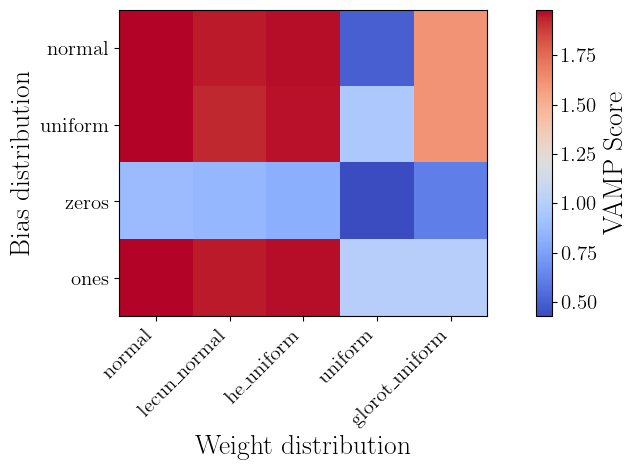

In [9]:
plot = 'imshow'  # 'surface' or 'imshow'

if plot == 'surface':
    omw, omb = np.meshgrid(range(len(dist_w_list)), range(len(dist_b_list)))

    fig, ax = plt.subplots()

    cp = ax.plot_surface(omw, omb, -vampscores_exp_ls.T, cmap=plt.cm.coolwarm)

    ax.set_xticklabels(dist_w_list, rotation=45, fontsize=15)
    ax.set_yticklabels(dist_b_list, fontsize=15)
    ax.xaxis.labelpad = 15
    ax.yaxis.labelpad = 15
    ax.zaxis.labelpad = 15
    ax.set_zticklabels([])
    cbar = fig.colorbar(cp, ax=ax, shrink=0.8, pad=0.1)
    cbar.set_label('VAMP Score', size=25)
    cbar.ax.tick_params(labelsize=15) 
    #fig.savefig(f'../figures/ou{dim}_gridsearch_distscales.pdf', bbox_inches='tight', dpi=300)
    plt.show()

if plot == 'imshow':

    fig, ax = plt.subplots()
    im = ax.imshow(vampscores_exp_ls.T, cmap='coolwarm', aspect='auto', origin='upper')

    ax.set_xticks(np.arange(len(dist_w_list)))
    ax.set_yticks(np.arange(len(dist_b_list)))
    ax.set_xticklabels(dist_w_list, rotation=45, ha="right", fontsize=15)
    ax.set_yticklabels(dist_b_list, fontsize=15)
    ax.set_xlabel('Weight distribution', fontsize=20)
    ax.set_ylabel('Bias distribution', fontsize=20)

    cbar = fig.colorbar(im, ax=ax, shrink=1, pad=0.1)
    cbar.set_label('VAMP Score', size=20)
    cbar.ax.tick_params(labelsize=15)
    #fig.savefig(f'../figures/ou{dim}_gridsearch_distdist.pdf', bbox_inches='tight', dpi=300)
    plt.tight_layout()
    plt.show()

In [4]:
#TODO: put here the dominant n eigenvalues of the Koopman operator

exact_eigvals_o = np.exp(exact_eigv_gen * dt)[::-1] 
print('Exact eigenvalues of operator: ', exact_eigvals_o)
print('Sum of exact eigenvalues of operator: ', np.sum(exact_eigvals_o))

Exact eigenvalues of operator:  [1.         0.86070798 0.77880078 0.74081822 0.67032005]
Sum of exact eigenvalues of operator:  4.05064702621382


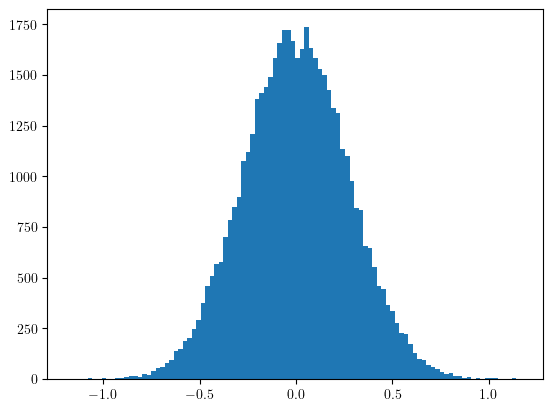

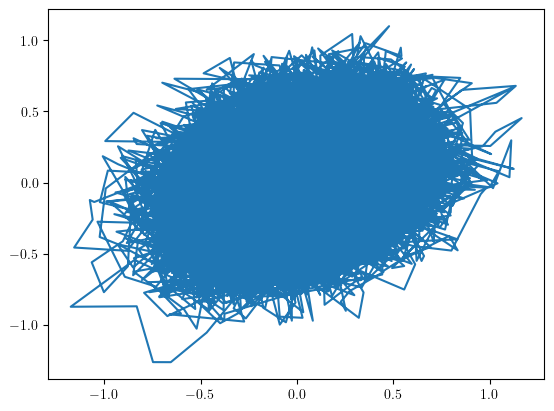

In [5]:
plt.hist(X[0, :], bins=100)
plt.show()

plt.plot(X[0, :], X[1, :])

## RaNNDy

In [5]:
## Run this cell to apply RaNNDy for the Koopman operator

random_state = 0  # Random state for reproducibility
n_eigfuncs = 5  # Number of eigenfunctions to compute
kwargs = {} # only needed for Hamiltonian operator

ranndy = RaNNDy(
    X=X,
    operator='koopman',
    hidden_sizes=[256, 512, 256],
    activation="tanh",
    init_weights_dist='lecun_normal', 
    init_weights_std=1.0,
    init_bias_dist='uniform',
    init_bias_std=1.0,
    random_state=random_state,
)

start_time = time.perf_counter()  
Kr, eigvals_rnn, eigvecs_rnn = ranndy.operator_eig_decomp(
    X=X,
    Y=Y,
    Z=None,
    params=None,
    n=n_eigfuncs,
    epsilon=1e-5,
    kwargs=kwargs)

end_time = time.perf_counter()  # End time for RNN eigendecomposition
time_rnn = end_time - start_time
print(f"RNN eigendecomposition time: {time_rnn:.2f} seconds")
print("Sum of Real Parts of RNN Eigenvalues:", np.sum(np.real(eigvals_rnn)))

RNN eigendecomposition time: 1.60 seconds
Sum of Real Parts of RNN Eigenvalues: 3.9369278


## VAMPnets

In [ ]:
## Run this cell to apply VAMPnets for Koopman operator  

vampnet = VAMPNets(X=X, 
                   hidden_sizes=[256, 512, 256, 5],
                   activation='tanh',
                   init_weights_dist='uniform', 
                   init_weights_std=1.0,
                   init_bias_dist='zeros',
                   init_bias_std=1.0,
                   batch_norm=False,
                   random_state=random_state)

## Operator eigendecomposition using VAMPNet

epochs = [20, 40, 60, 80, 100, 120]  # TODO: uncomment the list to train VAMPnets for different epochs
traces_vampnet = []
run_times = []

lr = 1e-2  # Learning rate for the optimizer; large lr leads to nan values so keep it small
optim = 'adam'  # Optimizer for training VAMPNet

for epoch in epochs:
   start_time = time.time()  # Start time for VAMPNet eigendecomposition

   params, loss = vampnet.training(X=X, Y=Y, n=n_eigfuncs, epochs=epoch, optim=optim, lr=lr, epsilon=1e-5)

   end_time = time.time()  # End time for VAMPNet eigendecomposition
   time_vampnet = end_time - start_time
   run_times.append(time_vampnet)
   traces_vampnet.append(loss[-1])
   print(f"VAMPNet eigendecomposition time: {time_vampnet:.2f} seconds")

## eigenfunctions using VAMPNet

Kv, eigvals_vampnet, eigvecs_vampnet = vampnet.koopman_approximation(params=params,
    X=X,
    Y=Y, n=n_eigfuncs)

Epoch 0, Loss: -1.6522
Epoch 10, Loss: -1.6567
VAMPNet eigendecomposition time: 39.13 seconds
Epoch 0, Loss: -1.6530
Epoch 10, Loss: -1.6437
Epoch 20, Loss: -1.6510
Epoch 30, Loss: -1.7147
VAMPNet eigendecomposition time: 79.77 seconds
Epoch 0, Loss: -1.6629
Epoch 10, Loss: -1.8344
Epoch 20, Loss: -2.0299
Epoch 30, Loss: -2.3611
Epoch 40, Loss: -2.6893
Epoch 50, Loss: -2.9672
VAMPNet eigendecomposition time: 120.93 seconds
Epoch 0, Loss: -2.5809
Epoch 10, Loss: -3.0373
Epoch 20, Loss: -3.0748
Epoch 30, Loss: -3.1243
Epoch 40, Loss: -3.1888
Epoch 50, Loss: -3.2441
Epoch 60, Loss: -3.2752
Epoch 70, Loss: -3.3136
VAMPNet eigendecomposition time: 176.35 seconds
Epoch 0, Loss: -2.8417
Epoch 10, Loss: -3.1967
Epoch 20, Loss: -3.3088
Epoch 30, Loss: -3.3830
Epoch 40, Loss: -3.4237
Epoch 50, Loss: -3.4613
Epoch 60, Loss: -3.4825
Epoch 70, Loss: -3.4892
Epoch 80, Loss: -3.5186
Epoch 90, Loss: -3.5282
VAMPNet eigendecomposition time: 218.31 seconds
Epoch 0, Loss: -2.8092
Epoch 10, Loss: -3.2763


In [ ]:
# print('eigvals of RaNNDy and sum their sum', np.log(eigvals_rnn) / dt, np.sum(eigvals_rnn))
# print('Trace of Kr: ', np.trace(Kr))

# print('eigvals of VAMPnets and sum their sum', np.log(eigvals_vampnet) / dt, np.sum(eigvals_vampnet))
# print('Trace of Kv: ', np.trace(Kv))

eigvals of RaNNDy and sum their sum [-1.11461304e-04+0.j -1.19026530e+00+0.j -2.00596976e+00+0.j
 -2.49772048e+00+0.j -2.99686384e+00+0.j] (4.226044+0j)
Trace of Kr:  4.92824


NameError: name 'eigvals_vampnet' is not defined

In [7]:
print('Eigenvalues Exact: ', exact_eigvals_o)
print('Eigenvalues RaNNDy: ', eigvals_rnn)
print('Eigenvalues VAMPnets: ', eigvals_vampnet)


Eigenvalues Exact:  [1.         0.86070798 0.77880078 0.74081822 0.67032005]
Eigenvalues RaNNDy:  [0.9999864 +0.j 0.84947157+0.j 0.74803084+0.j 0.70929414+0.j
 0.63014495+0.j]
Eigenvalues VAMPnets:  [0.99999994+0.j 0.84439546+0.j 0.74606615+0.j 0.7377879 +0.j
 0.64928764+0.j]


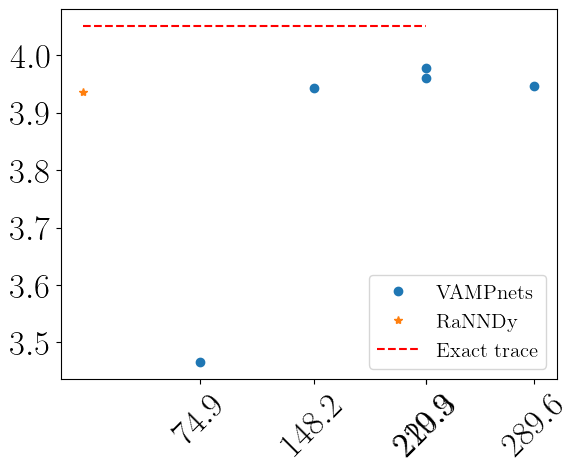

In [9]:
### Convergence plots

plt.figure()
plt.plot(run_times, np.array(np.real(traces_vampnet)), 'o', label='VAMPnets')
plt.plot(np.sum(np.real(eigvals_rnn)), '*', label='RaNNDy')
plt.hlines(np.sum(exact_eigvals_o), xmin=0, xmax=run_times[-1], colors='red', linestyles='--', label='Exact trace')
#plt.xlabel("Epochs (Time in sec.)", fontsize=30)
#plt.ylabel("VAMP score", fontsize=30)
plt.legend(fontsize=15, loc='lower right')
#labels = [f"{e} ({t:.2f})" for e, t in zip(epochs, run_times)]
plt.xticks(run_times, rotation=45, fontsize=25)
plt.yticks(fontsize=25)
#plt.savefig("../figures/ou2dcomp_lecun_normal.pdf", bbox_inches="tight",dpi=300)
plt.show()


In [8]:
exact_vamp = np.sum(exact_eigvals_o)
#dim = [1, 2, 3, 4]
error_ranndy = np.abs((np.sum(eigvals_rnn) - exact_vamp)/exact_vamp)
error_vampnet = np.abs((np.sum(eigvals_vampnet) - exact_vamp)/exact_vamp)

print('Error in RaNNDy approximation: ', error_ranndy)
print('Error in VAMPnets approximation: ', error_vampnet)

Error in RaNNDy approximation:  0.028074393
Error in VAMPnets approximation:  0.018048992


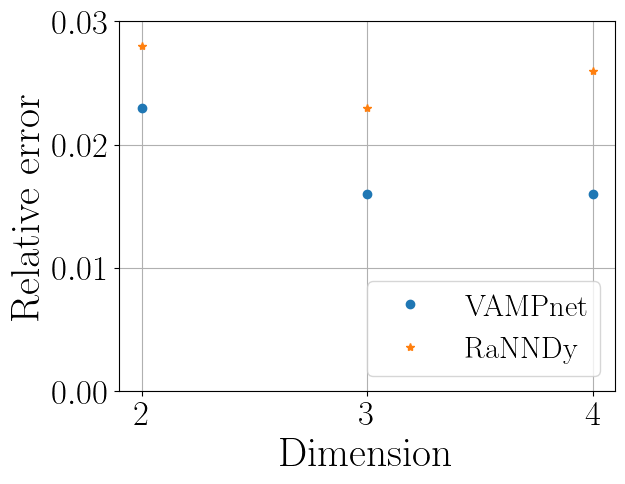

In [ ]:
## Error plots for different dimensions

import matplotlib.pyplot as plt
import numpy as np

dimensionss = [2, 3, 4]
errors_ranndy_list = [0.028, 0.023, 0.026]       #TODO: errors reported from different dimensions and experiments
errors_vampnet_list = [0.023, 0.016, 0.016]

plt.figure()
plt.plot(dimensionss, np.array(errors_vampnet_list), 'o', label='VAMPnet')
plt.plot(dimensionss, np.array(errors_ranndy_list), '*', label='RaNNDy')
plt.grid(which='major')
plt.grid(which='minor')
plt.ylabel("Relative error", fontsize=30)
plt.xlabel("Dimension", fontsize=30)
plt.legend(fontsize=22, loc='lower right')

plt.yticks(np.arange(0.00, 0.035, 0.01), fontsize=25)
plt.xticks(np.arange(2, 5, 1), fontsize=25)
#plt.savefig("../figures/OU_error_comp_5dom.pdf", bbox_inches="tight",dpi=300)
plt.show()

In [ ]:
### VAMPnets: divergence for normal and zeros with std 0.01

### Increasing number of neurons experiment

In [ ]:
# ## Experiments with increasing hidden neurons in RaNNDy

# hidden_sizes = [8, 32, 64, 100, 150, 200, 400, 600, 800]  # Hidden layer sizes
# random_state = 0  # Random state for reproducibility
# n_eigfuncs = 5  # Number of eigenfunctions to compute
# kwargs = {} # only needed for Hamiltonian operator

# traces_ranndy_neurons = []

# for hs in hidden_sizes:
#     ranndy = RaNNDy(
#             X=X,
#             operator='koopman',
#             hidden_sizes=[hs],
#             final_size=128,
#             activation='tanh',
#             init_weights_dist='lecun_normal', 
#             init_weights_std=1.0,
#             init_bias_dist='uniform',
#             init_bias_std=1.0,
#             random_state=random_state,
#         )

#     start_time = time.time()  # Start time for RNN eigendecomposition
#     # eigvals and eigenvectors approximation
#     Kr_exp, eigvals_rnn_exp, eigvecs_rnn_exp = ranndy.operator_eig_decomp(
#         X=X,
#         Y=Y,
#         Z=None,
#         params=None,
#         n=n_eigfuncs,
#         epsilon=1e-5,
#         kwargs=kwargs)
#     print(np.sum(eigvals_rnn_exp))
#     traces_ranndy_neurons.append(np.sum(eigvals_rnn_exp))

#     end_time = time.time()  # End time for RNN eigendecomposition
#     time_rnn = end_time - start_time
#     print(f"RNN eigendecomposition time: {time_rnn:.2f} seconds")

(4.4244995+0j)
RNN eigendecomposition time: 0.15 seconds
(4.6069617+0j)
RNN eigendecomposition time: 0.15 seconds
(4.634701+0j)
RNN eigendecomposition time: 0.15 seconds
(4.636556+0j)
RNN eigendecomposition time: 0.53 seconds
(4.6371245+0j)
RNN eigendecomposition time: 0.16 seconds
(4.639528+0j)
RNN eigendecomposition time: 0.17 seconds
(4.6397276+0j)
RNN eigendecomposition time: 0.63 seconds
(4.6386275+0.0009693409j)
RNN eigendecomposition time: 0.38 seconds
(4.638574+0j)
RNN eigendecomposition time: 1.16 seconds


/home/s2421480/Documents/Github_projects/ranndy/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/s2421480/Documents/Github_projects/ranndy/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


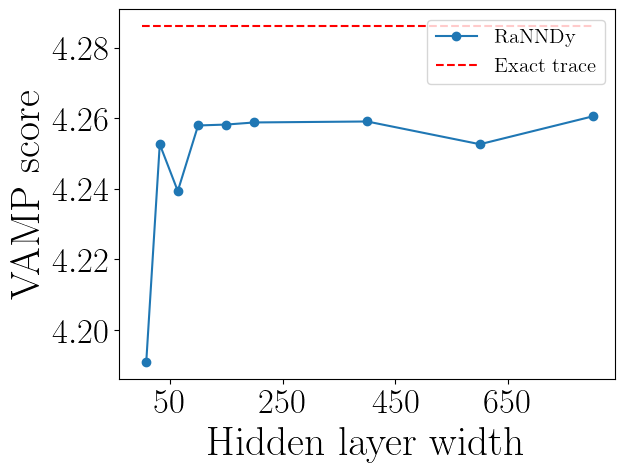

In [ ]:
# plt.figure()
# plt.plot(hidden_sizes, traces_ranndy_neurons, '-o', label='RaNNDy')
# plt.hlines(np.sum(exact_eigvals_o), xmin=0, xmax=hidden_sizes[-1], colors='red', linestyles='--', label='Exact trace')
# plt.xlabel("Hidden layer width", fontsize=30)
# plt.ylabel("VAMP score", fontsize=30)
# plt.legend(fontsize=15, loc='upper right')
# plt.xticks(np.arange(50, 800, 200),fontsize=25)
# plt.yticks( fontsize=25)
# #plt.savefig("../figures/hidden_convergence_dim4OU.pdf", bbox_inches="tight",dpi=300)
# plt.show()
